# Лабораторная работа №3 — Кластеризация, снижение размерности пространства признаков

## Датасет: Titanic (Пассажиры Титаника)

**Целевая переменная:** `survived` — выжил пассажир (1) или нет (0). В кластеризации она не используется при обучении, но помогает интерпретировать найденные группы пассажиров.

## Задачи
- Подготовить данные так же, как в предыдущих лабораторных работах.
- Снизить размерность признакового пространства до 2 компонент t-SNE.
- Выполнить кластеризацию в полученном t-SNE-пространстве, так как в лабораторной №1 этот метод лучше визуально разделил выживших и погибших.
- Применить два метода кластеризации из разных групп:
  - KMeans — метод, основанный на расстояниях между точками.
  - DBSCAN — метод, основанный на плотности точек.
- Подобрать количество кластеров для KMeans методом локтя.
- Подобрать параметры `eps` и `min_samples` для DBSCAN.
- Оценить качество кластеризации внутренними метриками.
- Визуализировать результаты кластеризации.

---
## 1. Импорт библиотек

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 6)

print('Библиотеки успешно загружены!')

Библиотеки успешно загружены!


---
## 2. Загрузка и подготовка данных

Используем тот же подход к очистке, что и в лабораторных работах №1–2: удаляем дублирующие или слишком неполные признаки, заполняем пропуски, удаляем выбросы по `fare`, кодируем категориальные признаки и стандартизируем данные.

In [98]:
df_raw = sns.load_dataset('titanic')

df = df_raw.copy()
cols_to_drop = ['deck', 'class', 'who', 'adult_male', 'alive', 'alone', 'embark_town']
df = df.drop(columns=cols_to_drop)

df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# Удаление выбросов по стоимости билета методом IQR
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df = df[(df['fare'] >= lower) & (df['fare'] <= upper)].copy()

# Кодирование признаков
df_encoded = df.copy()
df_encoded['sex'] = df_encoded['sex'].map({'male': 1, 'female': 0})
embarked_dummies = pd.get_dummies(df_encoded['embarked'], prefix='embarked', dtype=int)
df_encoded = pd.concat([df_encoded.drop(columns=['embarked']), embarked_dummies], axis=1)

feature_cols = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked_C', 'embarked_Q', 'embarked_S']
X = df_encoded[feature_cols]
y = df_encoded['survived']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Размер датасета после очистки: {X.shape[0]} строк × {X.shape[1]} признаков')
print(f'Пропуски в признаках: {X.isnull().sum().sum()}')
print(f'Баланс survived: {y.value_counts().to_dict()}')
X.head()

Размер датасета после очистки: 775 строк × 9 признаков
Пропуски в признаках: 0
Баланс survived: {0: 512, 1: 263}


,pclass,sex,age,sibsp,parch,fare,embarked_C,embarked_Q,embarked_S
0,3,1,22.0,1,0,7.2500,0,0,1
2,3,0,26.0,0,0,7.9250,0,0,1
3,1,0,35.0,1,0,53.1000,0,0,1
4,3,1,35.0,0,0,8.0500,0,0,1
5,3,1,28.0,0,0,8.4583,0,1,0


---
## 3. Снижение размерности t-SNE

В лабораторной работе №1 было видно, что t-SNE лучше разделяет выживших и погибших пассажиров, чем PCA и MDS. Поэтому для этой работы используем t-SNE как двумерное нелинейное представление данных и выполняем кластеризацию уже в этом пространстве.

Важно: целевая переменная `survived` не участвует в построении t-SNE и кластеризации. Она используется только для визуальной и численной оценки результата.

t-SNE-представление построено:
Размерность после снижения: 775 строк × 2 признака


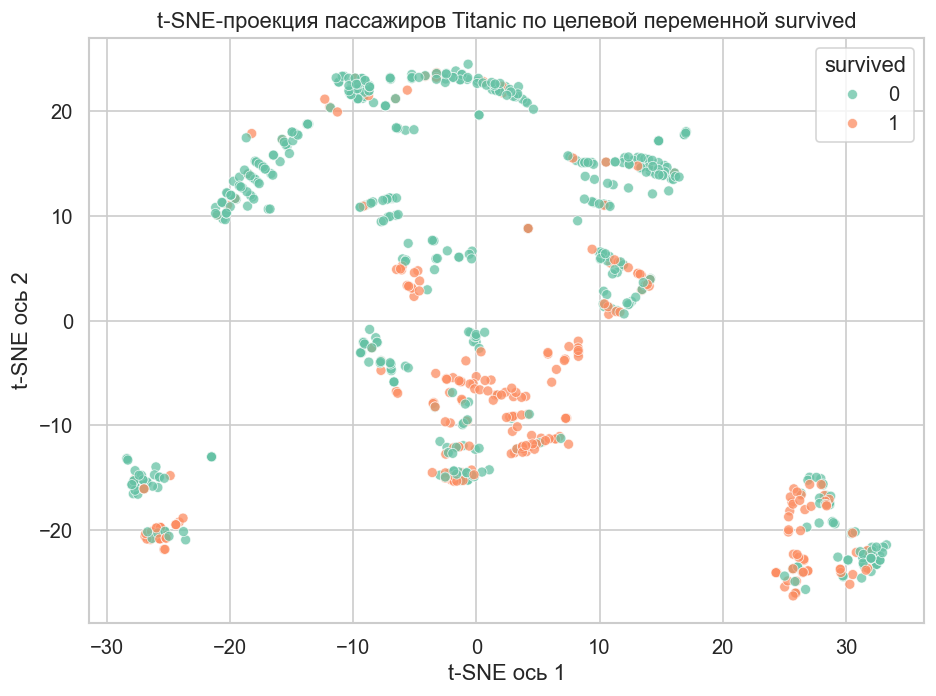

In [99]:
tsne = TSNE(n_components=2, perplexity=40, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'], index=X.index)
tsne_df['survived'] = y.values

print('t-SNE-представление построено:')
print(f'Размерность после снижения: {X_tsne.shape[0]} строк × {X_tsne.shape[1]} признака')

plt.figure(figsize=(8, 6))
sns.scatterplot(data=tsne_df, x='TSNE1', y='TSNE2', hue='survived', palette='Set2', alpha=0.75)
plt.title('t-SNE-проекция пассажиров Titanic по целевой переменной survived')
plt.xlabel('t-SNE ось 1')
plt.ylabel('t-SNE ось 2')
plt.legend(title='survived')
plt.tight_layout()
plt.show()

---
## 4. Метод KMeans

KMeans относится к методам, основанным на расстояниях между точками. Применим его к координатам `X_tsne`.

Количество кластеров выберем **методом локтя**. Для разных `k` считаем inertia — сумму квадратов расстояний точек до центров своих кластеров. При увеличении `k` inertia всегда уменьшается, поэтому ищем точку, после которой улучшение становится заметно слабее. Эта точка и называется «локтем».

На графике выбранное значение `k` будет отмечено красной вертикальной линией.

### 4.1 Базовое применение KMeans без подбора гиперпараметров

Сначала применим KMeans с заранее заданным количеством кластеров `k=3`. Это нужно, чтобы показать работу метода без настройки, а затем сравнить результат с вариантом, где `k` выбирается методом локтя.

Размеры базовых кластеров KMeans:
0    397
1    262
2    116
Name: count, dtype: int64


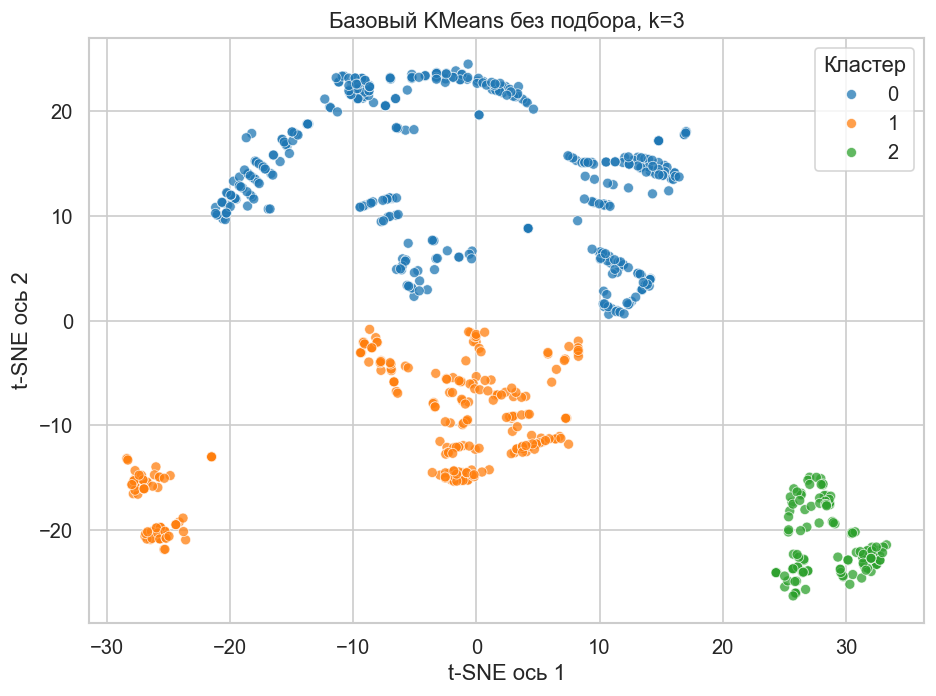

In [100]:
kmeans_base_k = 3
kmeans_base = KMeans(n_clusters=kmeans_base_k, random_state=42, n_init=20)
kmeans_base_labels = kmeans_base.fit_predict(X_tsne)
tsne_df['kmeans_base_cluster'] = kmeans_base_labels

print('Размеры базовых кластеров KMeans:')
print(pd.Series(kmeans_base_labels).value_counts().sort_index())

plt.figure(figsize=(8, 6))
sns.scatterplot(data=tsne_df, x='TSNE1', y='TSNE2', hue='kmeans_base_cluster', palette='tab10', alpha=0.75)
plt.title(f'Базовый KMeans без подбора, k={kmeans_base_k}')
plt.xlabel('t-SNE ось 1')
plt.ylabel('t-SNE ось 2')
plt.legend(title='Кластер')
plt.tight_layout()
plt.show()

Значения inertia для разных k:


,k,inertia
0,2,227503.20
1,3,123098.59
2,4,76429.84
3,5,37904.12
4,6,26950.48
5,7,20200.52
6,8,15828.29
7,9,12932.24
8,10,10556.31


Выбранное количество кластеров по методу локтя: k=5
Красная линия показывает точку, после которой дальнейшее увеличение k даёт уже менее выраженное снижение inertia.


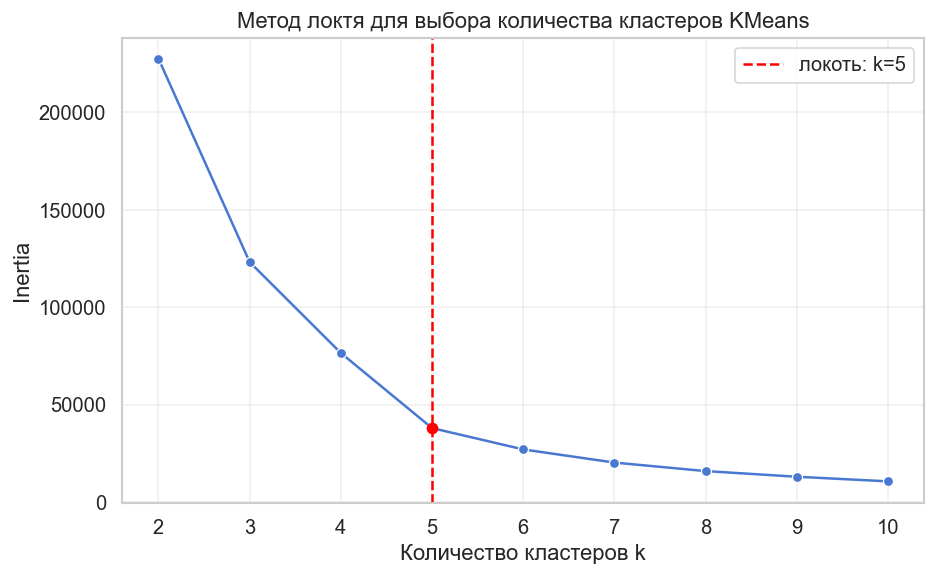

In [101]:
k_values = np.arange(2, 11)
kmeans_rows = []

for k in k_values:
    model = KMeans(n_clusters=int(k), random_state=42, n_init=20)
    labels = model.fit_predict(X_tsne)
    kmeans_rows.append({
        'k': int(k),
        'inertia': model.inertia_
    })

kmeans_scores = pd.DataFrame(kmeans_rows)

# Автоматическое определение «локтя»: точка с максимальным расстоянием
# до прямой, соединяющей первый и последний элементы графика inertia.
x = kmeans_scores['k'].to_numpy(dtype=float)
y_inertia = kmeans_scores['inertia'].to_numpy(dtype=float)
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y_inertia - y_inertia.min()) / (y_inertia.max() - y_inertia.min())
line_start = np.array([x_norm[0], y_norm[0]])
line_end = np.array([x_norm[-1], y_norm[-1]])
line_vec = line_end - line_start
points = np.column_stack([x_norm, y_norm])
distances_to_line = np.abs(np.cross(line_vec, points - line_start) / np.linalg.norm(line_vec))
elbow_index = int(np.argmax(distances_to_line))
selected_k = int(kmeans_scores.loc[elbow_index, 'k'])

print('Значения inertia для разных k:')
display(kmeans_scores.round(2))
print(f'Выбранное количество кластеров по методу локтя: k={selected_k}')
print('Красная линия показывает точку, после которой дальнейшее увеличение k даёт уже менее выраженное снижение inertia.')

plt.figure(figsize=(8, 5))
sns.lineplot(data=kmeans_scores, x='k', y='inertia', marker='o')
plt.axvline(selected_k, color='red', linestyle='--', label=f'локоть: k={selected_k}')
plt.scatter([selected_k], [kmeans_scores.loc[elbow_index, 'inertia']], color='red', zorder=5)
plt.title('Метод локтя для выбора количества кластеров KMeans')
plt.xlabel('Количество кластеров k')
plt.ylabel('Inertia')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Размеры кластеров KMeans:
0    160
1    200
2    116
3     74
4    225
Name: count, dtype: int64


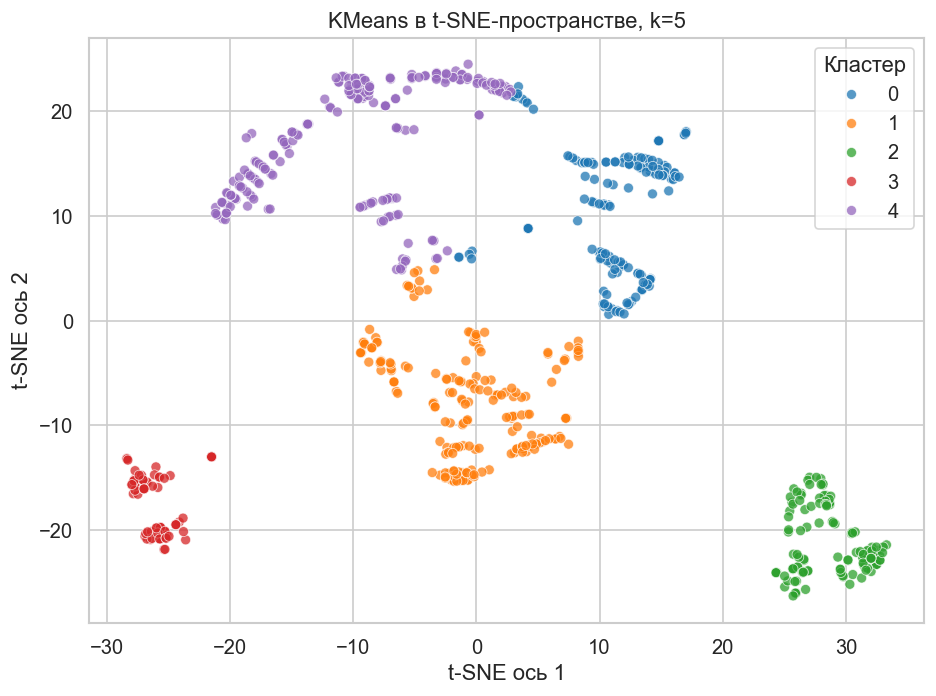

In [102]:
kmeans = KMeans(n_clusters=selected_k, random_state=42, n_init=20)
kmeans_labels = kmeans.fit_predict(X_tsne)
tsne_df['kmeans_cluster'] = kmeans_labels

print('Размеры кластеров KMeans:')
print(pd.Series(kmeans_labels).value_counts().sort_index())

plt.figure(figsize=(8, 6))
sns.scatterplot(data=tsne_df, x='TSNE1', y='TSNE2', hue='kmeans_cluster', palette='tab10', alpha=0.75)
plt.title(f'KMeans в t-SNE-пространстве, k={selected_k}')
plt.xlabel('t-SNE ось 1')
plt.ylabel('t-SNE ось 2')
plt.legend(title='Кластер')
plt.tight_layout()
plt.show()

---
## 5. Метод DBSCAN

DBSCAN относится к методам, основанным на плотности точек. Для него нужно подобрать два основных параметра:
- `min_samples` — сколько соседей нужно точке, чтобы считаться ядром плотной области;
- `eps` — радиус окрестности, в которой ищутся эти соседи.

Для подбора используем более устойчивый подход:
1. перебираем несколько разумных значений `min_samples`;
2. для каждого `min_samples` строим k-distance-график;
3. выбираем `eps` как точку «локтя» на этом графике;
4. дополнительно проверяем небольшую окрестность вокруг найденного `eps`;
5. выбираем интерпретируемое решение по внутренним метрикам: высокий silhouette, умеренная доля шума и не слишком сильное дробление на мелкие кластеры.

Целевая переменная `survived` при подборе DBSCAN не используется.

### 5.1 Базовое применение DBSCAN без подбора гиперпараметров

Сначала применим DBSCAN с заранее заданными параметрами `eps=1.0` и `min_samples=5`. Это базовый вариант без настройки. Далее параметры будут подобраны через k-distance-графики и проверку окрестности `eps`.

Размеры базовых кластеров DBSCAN (-1 означает шум):
-1     88
 0     17
 1     29
 2      9
 3     56
 4     33
 5     22
 6     10
 7     27
 8     42
 9     14
 10    23
 11    25
 12    55
 13    11
 14    34
 15    39
 16    14
 17    10
 18    15
 19     8
 20    24
 21     7
 22    22
 23     6
 24     7
 25    13
 26    11
 27    11
 28     5
 29    10
 30     7
 31     5
 32    11
 33     5
 34     7
 35    10
 36     5
 37     6
 38     6
 39     5
 40     6
 41     5
Name: count, dtype: int64


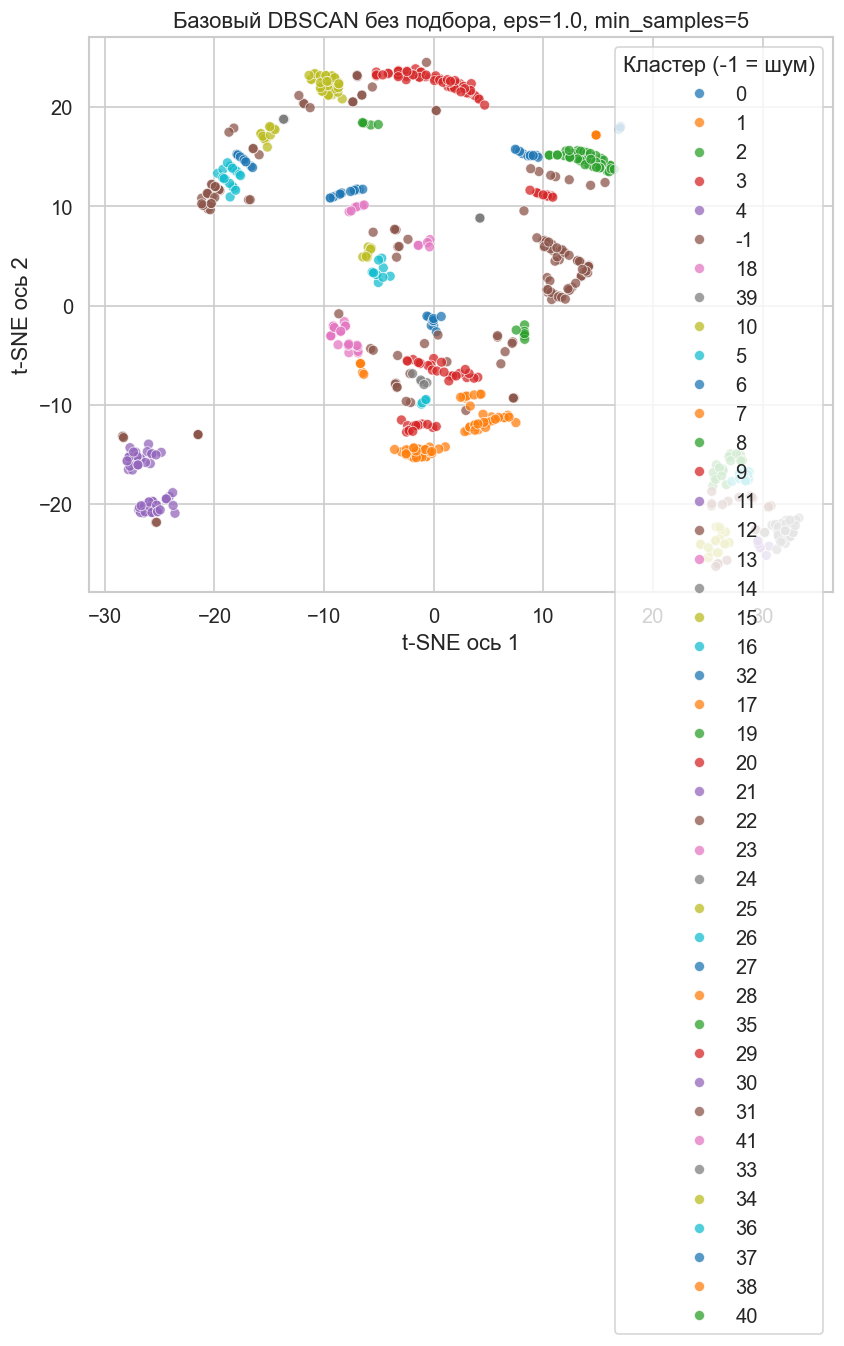

In [103]:
dbscan_base_eps = 1.0
dbscan_base_min_samples = 5
dbscan_base = DBSCAN(eps=dbscan_base_eps, min_samples=dbscan_base_min_samples)
dbscan_base_labels = dbscan_base.fit_predict(X_tsne)
tsne_df['dbscan_base_cluster'] = dbscan_base_labels

print('Размеры базовых кластеров DBSCAN (-1 означает шум):')
print(pd.Series(dbscan_base_labels).value_counts().sort_index())

plot_df = tsne_df.copy()
plot_df['dbscan_base_cluster_label'] = plot_df['dbscan_base_cluster'].astype(str)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_df,
    x='TSNE1',
    y='TSNE2',
    hue='dbscan_base_cluster_label',
    palette='tab10',
    alpha=0.75
)
plt.title(f'Базовый DBSCAN без подбора, eps={dbscan_base_eps}, min_samples={dbscan_base_min_samples}')
plt.xlabel('t-SNE ось 1')
plt.ylabel('t-SNE ось 2')
plt.legend(title='Кластер (-1 = шум)')
plt.tight_layout()
plt.show()

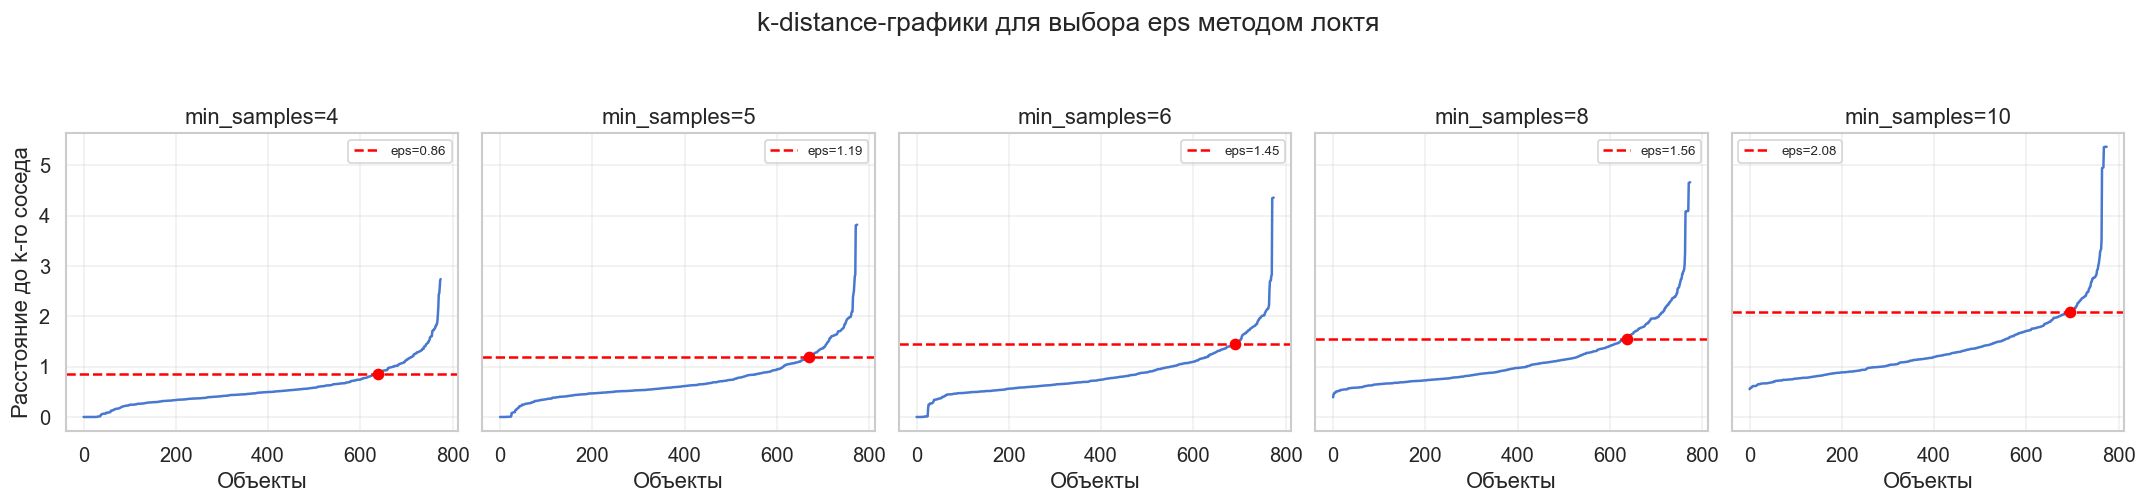

Значения eps, найденные методом локтя:


,min_samples,eps_elbow
0,4,0.864
1,5,1.188
2,6,1.447
3,8,1.558
4,10,2.080


In [104]:
def find_elbow_eps(sorted_distances):
    """Находит точку локтя как максимальное расстояние до прямой между концами графика."""
    x = np.arange(len(sorted_distances), dtype=float)
    y = np.asarray(sorted_distances, dtype=float)

    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())
    points = np.column_stack([x_norm, y_norm])

    line_start = points[0]
    line_end = points[-1]
    line_vec = line_end - line_start
    distances_to_line = np.abs(np.cross(line_vec, points - line_start) / np.linalg.norm(line_vec))
    elbow_index = int(np.argmax(distances_to_line))
    return float(sorted_distances[elbow_index]), elbow_index

min_samples_values = [4, 5, 6, 8, 10]
kdistance_rows = []

fig, axes = plt.subplots(1, len(min_samples_values), figsize=(18, 4), sharey=True)

for ax, min_samples in zip(axes, min_samples_values):
    neighbors = NearestNeighbors(n_neighbors=min_samples)
    distances, indices = neighbors.fit(X_tsne).kneighbors(X_tsne)
    k_distances_current = np.sort(distances[:, min_samples - 1])
    eps_elbow, elbow_index = find_elbow_eps(k_distances_current)

    kdistance_rows.append({
        'min_samples': min_samples,
        'eps_elbow': eps_elbow,
        'elbow_index': elbow_index
    })

    ax.plot(k_distances_current)
    ax.axhline(eps_elbow, color='red', linestyle='--', label=f'eps={eps_elbow:.2f}')
    ax.scatter([elbow_index], [eps_elbow], color='red', zorder=5)
    ax.set_title(f'min_samples={min_samples}')
    ax.set_xlabel('Объекты')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel('Расстояние до k-го соседа')
plt.suptitle('k-distance-графики для выбора eps методом локтя', y=1.05)
plt.tight_layout()
plt.show()

kdistance_df = pd.DataFrame(kdistance_rows)
print('Значения eps, найденные методом локтя:')
display(kdistance_df[['min_samples', 'eps_elbow']].round(3))

In [105]:
eps_multipliers = np.array([0.80, 0.90, 1.00, 1.10, 1.20])
dbscan_rows = []

for _, params in kdistance_df.iterrows():
    min_samples = int(params['min_samples'])
    eps_center = float(params['eps_elbow'])
    eps_candidates = np.unique(np.round(eps_center * eps_multipliers, 2))

    for eps in eps_candidates:
        model = DBSCAN(eps=float(eps), min_samples=min_samples)
        labels = model.fit_predict(X_tsne)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_share = np.mean(labels == -1)

        row = {
            'eps': float(eps),
            'min_samples': min_samples,
            'n_clusters': n_clusters,
            'noise_share': noise_share
        }

        mask = labels != -1
        labels_without_noise = labels[mask]
        X_without_noise = X_tsne[mask]

        if n_clusters >= 2 and len(set(labels_without_noise)) >= 2:
            row['silhouette'] = silhouette_score(X_without_noise, labels_without_noise)
            row['davies_bouldin'] = davies_bouldin_score(X_without_noise, labels_without_noise)
            row['calinski_harabasz'] = calinski_harabasz_score(X_without_noise, labels_without_noise)
        else:
            row['silhouette'] = np.nan
            row['davies_bouldin'] = np.nan
            row['calinski_harabasz'] = np.nan

        dbscan_rows.append(row)

dbscan_scores = pd.DataFrame(dbscan_rows)
valid_dbscan = dbscan_scores.dropna(subset=['silhouette']).copy()

# Отбрасываем крайние варианты: один огромный кластер, почти весь датасет как шум
# или слишком сильное дробление на множество мелких групп.
interpretable_dbscan = valid_dbscan[
    (valid_dbscan['n_clusters'] >= 2) &
    (valid_dbscan['n_clusters'] <= 10) &
    (valid_dbscan['noise_share'] >= 0.02) &
    (valid_dbscan['noise_share'] <= 0.40)
].copy()

if len(interpretable_dbscan) == 0:
    interpretable_dbscan = valid_dbscan[
        (valid_dbscan['n_clusters'] >= 2) &
        (valid_dbscan['n_clusters'] <= 14) &
        (valid_dbscan['noise_share'] <= 0.55)
    ].copy()

if len(interpretable_dbscan) == 0:
    interpretable_dbscan = valid_dbscan.copy()

# Итоговый рейтинг: silhouette важен, но штрафуем слишком большую долю шума
# и чрезмерное дробление на кластеры.
interpretable_dbscan['selection_score'] = (
    interpretable_dbscan['silhouette']
    - 0.30 * interpretable_dbscan['noise_share']
    - 0.015 * np.maximum(interpretable_dbscan['n_clusters'] - 6, 0)
)

best_dbscan_row = interpretable_dbscan.sort_values(
    ['selection_score', 'silhouette', 'davies_bouldin'],
    ascending=[False, False, True]
).iloc[0]
best_eps = float(best_dbscan_row['eps'])
best_min_samples = int(best_dbscan_row['min_samples'])

print('Лучшие варианты DBSCAN по комбинированному критерию:')
display(
    interpretable_dbscan.sort_values('selection_score', ascending=False)
    .head(10)
    .round(3)
)
print(f'Лучшие параметры: eps={best_eps}, min_samples={best_min_samples}')

Лучшие варианты DBSCAN по комбинированному критерию:


,eps,min_samples,n_clusters,noise_share,silhouette,davies_bouldin,calinski_harabasz,selection_score
24,2.5,10,10,0.021,0.439,0.632,1201.4,0.373


Лучшие параметры: eps=2.5, min_samples=10


Размеры кластеров DBSCAN (-1 означает шум):
-1     16
 0     23
 1    173
 2     15
 3    192
 4     36
 5     56
 6    116
 7     83
 8     34
 9     31
Name: count, dtype: int64


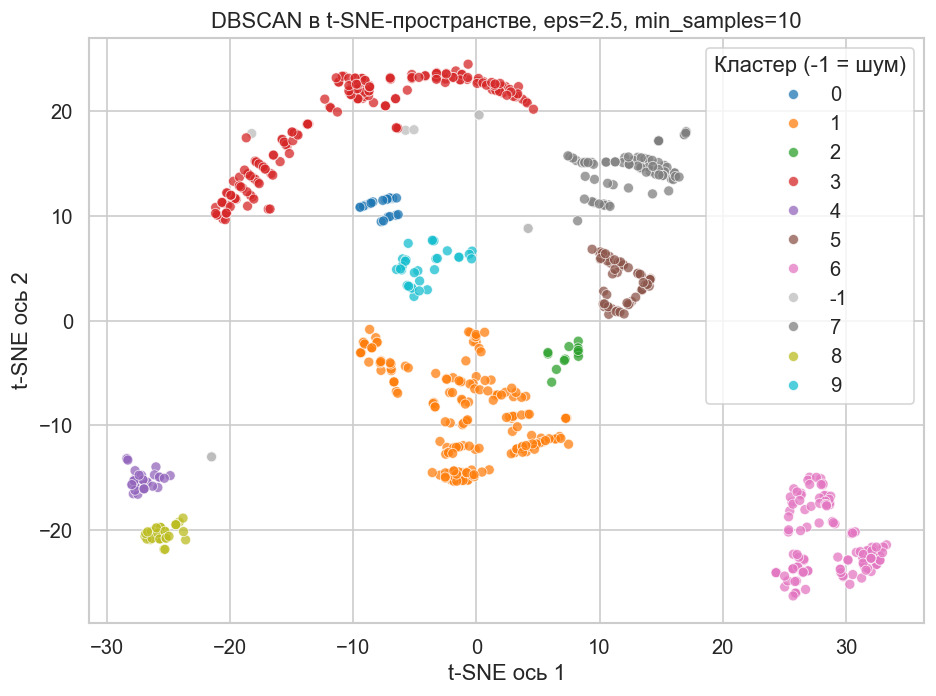

In [107]:
dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
dbscan_labels = dbscan.fit_predict(X_tsne)
tsne_df['dbscan_cluster'] = dbscan_labels

print('Размеры кластеров DBSCAN (-1 означает шум):')
print(pd.Series(dbscan_labels).value_counts().sort_index())

plot_df = tsne_df.copy()
plot_df['dbscan_cluster_label'] = plot_df['dbscan_cluster'].astype(str)
unique_labels = sorted(plot_df['dbscan_cluster'].unique())
colors = sns.color_palette('tab10', n_colors=max(1, len([v for v in unique_labels if v != -1])))
palette = {'-1': '#BDBDBD'}
color_index = 0
for label in unique_labels:
    if label == -1:
        continue
    palette[str(label)] = colors[color_index % len(colors)]
    color_index += 1

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_df,
    x='TSNE1',
    y='TSNE2',
    hue='dbscan_cluster_label',
    palette=palette,
    alpha=0.75
)
plt.title(f'DBSCAN в t-SNE-пространстве, eps={best_eps}, min_samples={best_min_samples}')
plt.xlabel('t-SNE ось 1')
plt.ylabel('t-SNE ось 2')
plt.legend(title='Кластер (-1 = шум)')
plt.tight_layout()
plt.show()

---
## 6. Оценка качества кластеризации

Для оценки используем внутренние метрики кластеризации:
- **Silhouette score** — чем выше, тем лучше разделены кластеры.
- **Davies-Bouldin index** — чем ниже, тем лучше.
- **Calinski-Harabasz index** — чем выше, тем лучше.

Эти метрики оценивают качество найденных кластеров по их компактности и разделимости, без использования целевой переменной `survived`.

In [108]:
def clustering_metrics(name, labels, X_data):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_share = np.mean(labels == -1)
    result = {
        'Метод': name,
        'Кластеров': n_clusters,
        'Доля шума': noise_share
    }

    mask = labels != -1
    labels_eval = labels[mask]
    X_eval = X_data[mask]

    if len(set(labels_eval)) >= 2:
        result['Silhouette'] = silhouette_score(X_eval, labels_eval)
        result['Davies-Bouldin'] = davies_bouldin_score(X_eval, labels_eval)
        result['Calinski-Harabasz'] = calinski_harabasz_score(X_eval, labels_eval)
    else:
        result['Silhouette'] = np.nan
        result['Davies-Bouldin'] = np.nan
        result['Calinski-Harabasz'] = np.nan

    return result

metrics_df = pd.DataFrame([
    clustering_metrics(f'KMeans базовый (k={kmeans_base_k})', kmeans_base_labels, X_tsne),
    clustering_metrics(f'KMeans с подбором (k={selected_k})', kmeans_labels, X_tsne),
    clustering_metrics(f'DBSCAN базовый (eps={dbscan_base_eps}, min_samples={dbscan_base_min_samples})', dbscan_base_labels, X_tsne),
    clustering_metrics(f'DBSCAN с подбором (eps={best_eps}, min_samples={best_min_samples})', dbscan_labels, X_tsne)
])

display(metrics_df.round(3))

,Метод,Кластеров,Доля шума,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans базовый (k=3),3,0.000,0.501,0.803,851.470
1,KMeans с подбором (k=5),5,0.000,0.614,0.518,1811.717
2,"DBSCAN базовый (eps=1.0, min_samples=5)",42,0.114,0.551,0.546,3950.011
3,"DBSCAN с подбором (eps=2.5, min_samples=10)",10,0.021,0.439,0.632,1201.400


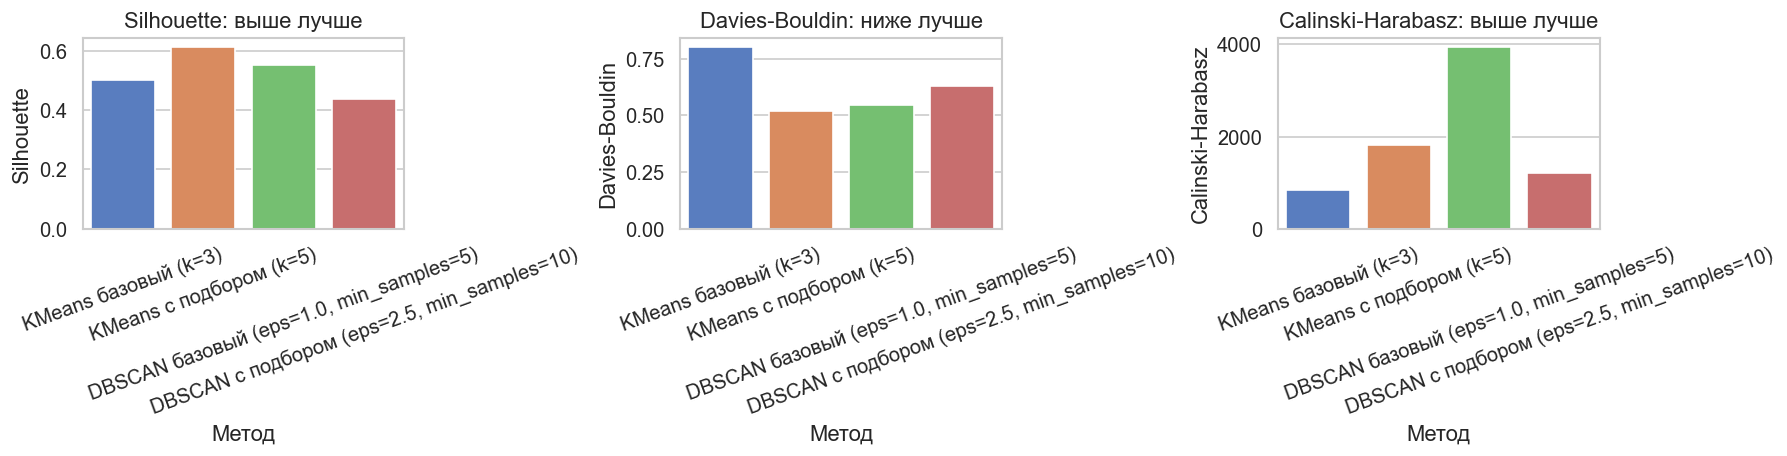

In [109]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=metrics_df, x='Метод', y='Silhouette', ax=axes[0], palette='muted')
axes[0].set_title('Silhouette: выше лучше')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=metrics_df, x='Метод', y='Davies-Bouldin', ax=axes[1], palette='muted')
axes[1].set_title('Davies-Bouldin: ниже лучше')
axes[1].tick_params(axis='x', rotation=20)

sns.barplot(data=metrics_df, x='Метод', y='Calinski-Harabasz', ax=axes[2], palette='muted')
axes[2].set_title('Calinski-Harabasz: выше лучше')
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

### Почему базовый DBSCAN может выглядеть лучше по метрикам

Если DBSCAN разбивает данные на много маленьких плотных кластеров, внутренние метрики могут стать лучше: точки внутри каждого маленького кластера находятся близко друг к другу, а расстояния между такими группами достаточно большие. Поэтому **Silhouette** и **Calinski-Harabasz** могут вырасти, даже если результат хуже интерпретируется.

Это не означает, что базовый DBSCAN обязательно лучше. Для итогового вывода нужно учитывать не только значения метрик, но и:
- количество найденных кластеров;
- долю шума `-1`;
- размер кластеров;
- понятность профиля кластеров по исходным признакам.

В этой работе метрики показывают геометрическое качество разбиения, а таблица размеров и профиль кластеров помогают понять, насколько результат удобно объяснять содержательно.